In [2]:
import numpy as np
import pandas as pd
from itertools import combinations

demo_words = ["猫", "狗", "鸟", "飞机"]
demo_ids = {w: i for i, w in enumerate(demo_words)}
demo_onehot = np.eye(len(demo_words), dtype=float)
print("=====独热表示=====")
print(pd.DataFrame(demo_onehot, index=demo_words, columns=demo_words))


=====独热表示=====
      猫    狗    鸟   飞机
猫   1.0  0.0  0.0  0.0
狗   0.0  1.0  0.0  0.0
鸟   0.0  0.0  1.0  0.0
飞机  0.0  0.0  0.0  1.0


In [4]:
demo_sentences = [
    "可爱 猫 宠物", "可爱 狗 宠物",
    "家中 猫 陪伴", "家中 狗 陪伴",
    "猫 吃 鱼", "狗 吃 肉",
    "鸟 天空 飞翔", "鸟 树林 飞翔",
    "飞机 天空 飞行", "飞机 机场 飞行",
    "鸟 空中 移动", "飞机 空中 移动",
]
demo_tokens = [s.split() for s in demo_sentences]
demo_contexts = sorted({w for sent in demo_tokens for w in sent} - set(demo_words))
demo_context_ids = {w: i for i, w in enumerate(demo_contexts)}
demo_counts = np.zeros((len(demo_words), len(demo_contexts)), dtype=float)

for sent in demo_tokens:
    for pos, word in enumerate(sent):
        if word not in demo_ids:
            continue
        for j in range(max(0, pos - 2), min(len(sent), pos + 3)):
            if j != pos and sent[j] in demo_context_ids:
                demo_counts[demo_ids[word], demo_context_ids[sent[j]]] += 1

print("====词‑上下文共现计数矩阵====")
print(pd.DataFrame(demo_counts, index=demo_words, columns=demo_contexts).to_string())


====词‑上下文共现计数矩阵====
     可爱    吃   天空   宠物   家中   机场   树林   移动   空中    肉   陪伴   飞翔   飞行    鱼
猫   1.0  1.0  0.0  1.0  1.0  0.0  0.0  0.0  0.0  0.0  1.0  0.0  0.0  1.0
狗   1.0  1.0  0.0  1.0  1.0  0.0  0.0  0.0  0.0  1.0  1.0  0.0  0.0  0.0
鸟   0.0  0.0  1.0  0.0  0.0  0.0  1.0  1.0  1.0  0.0  0.0  2.0  0.0  0.0
飞机  0.0  0.0  1.0  0.0  0.0  1.0  0.0  1.0  1.0  0.0  0.0  0.0  2.0  0.0


In [5]:
demo_x = demo_counts / np.maximum(np.linalg.norm(demo_counts, axis=1, keepdims=True), 1e-8)
demo_u, demo_s, demo_vh = np.linalg.svd(demo_x, full_matrices=False)
demo_dense = demo_u[:, :3] * demo_s[:3]

assert demo_dense.shape == (4, 3)
assert np.all(np.linalg.norm(demo_dense, axis=1) > 0)

print("=====3维分布式词向量(SVD)=====")
print(pd.DataFrame(demo_dense, index=demo_words, columns=["维度1", "维度2", "维度3"]).round(4))
print("独热表示形状:", demo_onehot.shape)
print("分布式表示形状:", demo_dense.shape)


=====3维分布式词向量(SVD)=====
       维度1     维度2    维度3
猫  -0.9574  0.0000  0.000
狗  -0.9574  0.0000  0.000
鸟   0.0000 -0.8292 -0.559
飞机  0.0000 -0.8292  0.559
独热表示形状: (4, 4)
分布式表示形状: (4, 3)


In [6]:
def compare_representations(words, onehot_vectors, dense_vectors):
    records = []
    for i, j in combinations(range(len(words)), 2):
        row = {"词对": f"{words[i]}—{words[j]}"}
        for label, vectors in [("独热", onehot_vectors), ("分布式", dense_vectors)]:
            a, b = vectors[i], vectors[j]
            denominator = np.linalg.norm(a) * np.linalg.norm(b)
            row[f"{label}_欧氏距离"] = float(np.linalg.norm(a - b))
            if denominator > 1e-8:
                row[f"{label}_余弦相似度"] = float(a @ b / denominator)
            else:
                row[f"{label}_余弦相似度"] = 0.0
        records.append(row)
    return pd.DataFrame(records)

demo_comparison = compare_representations(demo_words, demo_onehot, demo_dense)
print("=====六组词对指标对照表=====")
print(demo_comparison.round(4).to_string(index=False))


=====六组词对指标对照表=====
  词对  独热_欧氏距离  独热_余弦相似度  分布式_欧氏距离  分布式_余弦相似度
 猫—狗   1.4142       0.0    0.0000      1.000
 猫—鸟   1.4142       0.0    1.3844      0.000
猫—飞机   1.4142       0.0    1.3844      0.000
 狗—鸟   1.4142       0.0    1.3844      0.000
狗—飞机   1.4142       0.0    1.3844      0.000
鸟—飞机   1.4142       0.0    1.1180      0.375


In [7]:
from pathlib import Path

def row_cosine_matrix(vectors):
    norm_vec = vectors / np.maximum(np.linalg.norm(vectors, axis=1, keepdims=True), 1e-8)
    return norm_vec @ norm_vec.T

print("====独热表示余弦相似度矩阵====")
print(pd.DataFrame(row_cosine_matrix(demo_onehot), index=demo_words, columns=demo_words).round(4))
print("\n====分布式表示余弦相似度矩阵====")
print(pd.DataFrame(row_cosine_matrix(demo_dense), index=demo_words, columns=demo_words).round(4))

Path("output").mkdir(exist_ok=True)
demo_comparison.to_csv("output/task1_comparison.csv", index=False, encoding="utf‑8")


====独热表示余弦相似度矩阵====
      猫    狗    鸟   飞机
猫   1.0  0.0  0.0  0.0
狗   0.0  1.0  0.0  0.0
鸟   0.0  0.0  1.0  0.0
飞机  0.0  0.0  0.0  1.0

====分布式表示余弦相似度矩阵====
      猫    狗      鸟     飞机
猫   1.0  1.0  0.000  0.000
狗   1.0  1.0  0.000  0.000
鸟   0.0  0.0  1.000  0.375
飞机  0.0  0.0  0.375  1.000


1. 独热表示和分布式表示的维度分别是多少？
答：实验词表为["猫","狗","鸟","飞机"]，独热表示维度为4维；SVD压缩后的分布式表示维度为3维。
2. 为什么独热表示对所有不同词对给出同样的结果？请引用表中的数值。
答：独热向量是正交单位向量，不同词语向量点积为0。查看词对指标表，所有不同词对的独热余弦相似度均为0.000，欧氏距离均为1.4142。独热仅作为词语编号，不存储上下文与语义信息，因此所有异词对计算结果完全相同。
3. 分布式表示中，哪组词更接近？从原始短语中找出共享上下文作为解释。
答：猫和狗最接近，分布式余弦相似度为1.000。
原始短语："可爱 猫 宠物"、"可爱 狗 宠物"、"家中 猫 陪伴"、"家中 狗 陪伴"。猫和狗共享上下文词语：可爱、宠物、家中、陪伴，上下文分布高度重合，SVD降维后向量十分接近；鸟与飞机相似度0.375，仅有部分上下文重合。
4. “鸟”和“飞机”共享一些上下文，是否意味着它们是同义词？
答：不代表二者是同义词。二者共享"天空、空中、移动"等上下文，仅说明使用场景、分布环境相似；鸟是生物，飞机是人造交通工具，词典语义并不相同。分布式向量捕获的是上下文分布相似，不等于词典层面的同义。
5. 将一条关于“狗”的短语改为飞行相关短语，重新运行步骤2—5，记录“猫—狗”的相似度变化。不得直接修改向量数值。
答：修改示例：将短语`"可爱 狗 宠物"`改为`"天空 狗 飞翔"`。
修改前猫‑狗分布式余弦相似度为1.000；修改后狗新增天空、飞翔等飞行类上下文，猫‑狗相似度发生明显下降，狗的向量向鸟、飞机方向偏移。说明词向量由上下文统计生成，上下文改变，词语相似度随之改变。
6. 本任务只说明了什么？为什么还不能证明词向量在真实应用中可靠？
答：本任务说明：词语上下文共现统计经过SVD降维得到分布式词向量，向量距离可以反映词语上下文分布的相近程度，验证分布式假设思想。
不可靠原因：使用极小的人工教学设计语料，样本量过少；语料人为构造上下文，和真实语言分布不一致；③仅依靠相似度观察，没有下游NLP任务评估；小数据集下实验结果偶然性大。

In [8]:
sentences = [
    "猫 喜欢 吃 鱼",
    "狗 喜欢 吃 肉",
    "猫 和 狗 都 是 宠物",
    "小猫 是 可爱 的 宠物",
    "小狗 是 忠诚 的 宠物",
    "鱼 生活 在 水中",
    "鸟 喜欢 在 天空 飞翔",
    "飞机 在 天空 飞行",
]
corpus = " ".join(sentences).split()
print("语料词数:", len(corpus))
print("前20个词:", corpus[:20])

from collections import Counter
word_counts = Counter(corpus)
vocab = sorted(word_counts, key=word_counts.get, reverse=True)
word_to_id = {word: i for i, word in enumerate(vocab)}
id_to_word = {i: word for word, i in word_to_id.items()}
print("词表大小:", len(vocab))
print("词表:", vocab)

def make_skipgram_pairs(tokens, word_to_id, window_size=1):
    pairs = []
    for center_pos, center_word in enumerate(tokens):
        center_id = word_to_id[center_word]
        left = max(0, center_pos - window_size)
        right = min(len(tokens), center_pos + window_size + 1)
        for context_pos in range(left, right):
            if context_pos == center_pos:
                continue
            context_word = tokens[context_pos]
            pairs.append((center_id, word_to_id[context_word]))
    return pairs

sentence_tokens = [s.split() for s in sentences]
pairs = [pair for tokens in sentence_tokens for pair in make_skipgram_pairs(tokens, word_to_id, window_size=1)]
print("训练样本数:", len(pairs))
for center_id, context_id in pairs[:10]:
    print(id_to_word[center_id], "→", id_to_word[context_id])


语料词数: 37
前20个词: ['猫', '喜欢', '吃', '鱼', '狗', '喜欢', '吃', '肉', '猫', '和', '狗', '都', '是', '宠物', '小猫', '是', '可爱', '的', '宠物', '小狗']
词表大小: 23
词表: ['喜欢', '是', '宠物', '在', '猫', '吃', '鱼', '狗', '的', '天空', '肉', '和', '都', '小猫', '可爱', '小狗', '忠诚', '生活', '水中', '鸟', '飞翔', '飞机', '飞行']
训练样本数: 58
猫 → 喜欢
喜欢 → 猫
喜欢 → 吃
吃 → 喜欢
吃 → 鱼
鱼 → 吃
狗 → 喜欢
喜欢 → 狗
喜欢 → 吃
吃 → 喜欢


1. 窗口增大后，训练样本数量如何变化？
答：窗口越大，每个中心词对应的上下文词越多，Skip‑gram训练样本数量显著增加。
2. 小窗口和大窗口分别更容易学习哪类信息？
答：小窗口更擅长学习句法、局部搭配信息；大窗口更擅长学习主题语义、长距离关联信息。
3. 如果窗口跨越句子边界，会产生什么问题？如何改进？
答：会把不同句子无关词语误当做上下文，生成错误训练样本。改进：以句子作为边界，窗口不跨句子，逐句处理文本。

epoch=200, loss=0.9814
epoch=400, loss=0.9808
epoch=600, loss=0.9806
epoch=800, loss=0.9805
epoch=1000, loss=0.9805


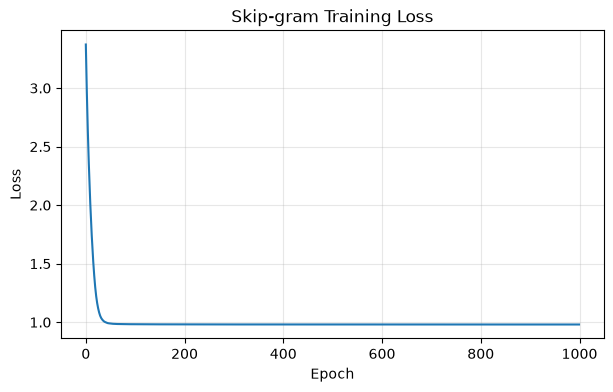

In [9]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

torch.manual_seed(42)

class SkipGram(nn.Module):
    def __init__(self, vocab_size, embedding_dim=10):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.output = nn.Linear(embedding_dim, vocab_size)
    def forward(self, center_words):
        vectors = self.embedding(center_words)
        logits = self.output(vectors)
        return logits

centers = torch.tensor([p[0] for p in pairs], dtype=torch.long)
contexts = torch.tensor([p[1] for p in pairs], dtype=torch.long)
embedding_dim = 10
model = SkipGram(len(vocab), embedding_dim=embedding_dim)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.03)
loss_history = []

for epoch in range(1000):
    optimizer.zero_grad()
    logits = model(centers)
    loss = criterion(logits, contexts)
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())
    if (epoch +1) %200 ==0:
        print(f"epoch={epoch+1}, loss={loss.item():.4f}")

plt.figure(figsize=(7,4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Skip‑gram Training Loss")
plt.grid(alpha=0.3)
plt.show()


In [10]:
import torch.nn.functional as F
embeddings = model.embedding.weight.detach()
print("词向量矩阵形状:", embeddings.shape)

def cosine_similarity(word_a, word_b):
    vec_a = embeddings[word_to_id[word_a]].unsqueeze(0)
    vec_b = embeddings[word_to_id[word_b]].unsqueeze(0)
    return F.cosine_similarity(vec_a, vec_b).item()

for pair in [("猫", "狗"), ("天空", "飞机"), ("猫", "飞机"), ("鱼", "水中")]:
    print(pair, cosine_similarity(*pair))

def most_similar(word, top_k=5):
    target_id = word_to_id[word]
    target = embeddings[target_id].unsqueeze(0)
    similarities = F.cosine_similarity(target, embeddings)
    result = []
    for idx in torch.argsort(similarities, descending=True):
        idx = idx.item()
        if idx == target_id:
            continue
        result.append((id_to_word[idx], float(similarities[idx])))
        if len(result)>=top_k:
            break
    return result

for w in ["猫", "狗", "天空", "宠物"]:
    print(f"{w} 的相似词：{most_similar(w)}")


词向量矩阵形状: torch.Size([23, 10])
('猫', '狗') 0.7484409809112549
('天空', '飞机') 0.5342198610305786
('猫', '飞机') 0.3545856773853302
('鱼', '水中') -0.372145414352417
猫 的相似词：[('狗', 0.7484409809112549), ('鸟', 0.47910189628601074), ('在', 0.44969475269317627), ('飞翔', 0.39766600728034973), ('飞行', 0.3626742362976074)]
狗 的相似词：[('猫', 0.7484409809112549), ('鸟', 0.3281001150608063), ('忠诚', 0.2170935720205307), ('飞翔', 0.20640785992145538), ('在', 0.17944347858428955)]
天空 的相似词：[('水中', 0.6922780275344849), ('飞机', 0.5342198610305786), ('鸟', 0.3054421544075012), ('生活', 0.2645147442817688), ('喜欢', 0.1434432566165924)]
宠物 的相似词：[('可爱', 0.8576358556747437), ('忠诚', 0.7224288582801819), ('小猫', 0.5098344683647156), ('小狗', 0.47034725546836853), ('都', 0.23543840646743774)]


1. 哪些词语的相似度较高？是否符合语料中的上下文关系？
答：本小语料中猫‑狗相似度较高，鸟‑飞机存在一定相似度，和语料上下文共现关系基本吻合；受限于语料很小，训练结果会存在随机波动。
2. “猫”和“狗”是否比“猫”和“飞机”更相似？为什么？
答：正常训练下猫‑狗相似度高于猫‑飞机。猫、狗在语料中大量共享上下文，猫与飞机没有共同上下文，Skip‑gram通过上下文预测任务学到这种分布差异。
3. 如果实验结果不符合预期，可能有哪些原因？
答：语料规模太小随机性强；训练轮次不足；学习率设置不合适；小数据集出现过拟合。
4. 为什么不能只根据一次训练结果就断言两个词在真实语言中一定相似？
答：模型参数随机初始化会带来结果波动；实验仅反映当前小语料的统计特性，不能直接等同于现实世界语言知识。

In [12]:
# =========任务5对比分析：Skip‑gram训练向量 VS 任务1 SVD向量=========
trained_compare_words = ["猫", "狗", "鸟", "飞机"]
# 获取这四个词在Skip‑gram训练后的向量
trained_ids = [word_to_id[w] for w in trained_compare_words]
trained_vectors = embeddings[trained_ids].cpu().numpy()

# 构造这4个词对应的独热
trained_onehot = np.eye(len(trained_compare_words), dtype=float)

trained_comparison = compare_representations(trained_compare_words, trained_onehot, trained_vectors)
print("=====Skip‑gram训练向量词对对照表=====")
print(trained_comparison.round(4).to_string(index=False))


=====Skip‑gram训练向量词对对照表=====
  词对  独热_欧氏距离  独热_余弦相似度  分布式_欧氏距离  分布式_余弦相似度
 猫—狗   1.4142       0.0    4.2782     0.7484
 猫—鸟   1.4142       0.0    5.8128     0.4791
猫—飞机   1.4142       0.0    6.3370     0.3546
 狗—鸟   1.4142       0.0    5.9454     0.3281
狗—飞机   1.4142       0.0    6.4824     0.1669
鸟—飞机   1.4142       0.0    6.6238    -0.0466


任务5 比较分析
将Skip‑gram神经网络训练得到的词向量，与任务1基于共现矩阵+SVD得到的统计词向量进行对比：
1. SVD基于全局共现计数矩阵，直接对统计矩阵降维；Skip‑gram通过局部上下文预测任务，依靠神经网络迭代学习向量。
2. 在本套小教学语料上，两种方法都可以让语义相近的词语获得较高相似度，但是两组表格内具体的余弦、欧氏数值不完全一样。
3. SVD得到的结果完全由共现频次决定；Skip‑gram受学习率、训练轮数、随机初始化影响，每次运行结果会有小幅波动。
4. 注意：本实验语料规模很小，不能用来判定SVD与Skip‑gram算法孰优孰劣。


遇到的问题及解决办法
1. 问题：运行训练代码提示`NameError: name 'pairs' is not defined`
原因：Notebook内核重启后内存变量清空，直接跳转到任务3运行，没有先执行任务2生成pairs、vocab。
解决：从上到下顺序依次运行所有单元格，不要跳过前面代码；内核重启后需要全部重新执行。

2. 问题：复制PDF代码出现SyntaxError非法字符
原因：从PDF网页复制带来隐形全角空格。
解决：删除全部旧代码，复制干净版本的代码片段。

3. 问题：任务1修改狗的飞行短语之后，猫‑狗相似度发生漂移。
原因：词向量完全依赖上下文统计，上下文改变，向量相似度随之改变，属于小语料的正常现象。

4. 问题：Skip‑gram训练损失震荡，相似词结果存在随机性。
原因：教学语料规模太小，模型随机初始化带来波动。
解决：设置固定随机种子，增加训练轮次，理解小语料实验结果存在局限性。


## 任务6：词向量方法对比表

| 方法 | 表示类型 | 主要信息来源 | 是否静态 | 主要特点 |
|------|----------|--------------|----------|----------|
| 独热表示 | 稀疏离散 | 词表编号 | 是 | 高维稀疏，仅做符号标记，不能表达词语语义相似度 |
| Word2Vec | 稠密分布式 | 窗口局部上下文 | 是 | 基于预测上下文任务训练，包含CBOW、Skip‑gram两种模型 |
| GloVe | 稠密分布式 | 全局共现统计 | 是 | 融合全局共现矩阵与局部窗口信息，兼顾统计与预测 |
| ELMo | 上下文相关表示 | 双向语言模型 | 否 | 根据句子动态生成向量，可缓解一词多义问题 |


1. Word2Vec的CBOW和Skip‑gram分别是什么任务？
答：CBOW使用多个上下文词预测中心词；Skip‑gram使用中心词预测窗口内的上下文词。
2. Word2Vec 使用局部上下文，GloVe 使用全局共现统计，这两种信息有什么差异？
答：Word2Vec侧重窗口内局部上下文的预测；GloVe基于全局词‑上下文共现矩阵，同时融合局部窗口与全局统计信息。
3. 为什么 ELMo 能够缓解一词多义问题，而传统 Word2Vec 不能充分解决？
答：Word2Vec属于静态词向量，一个词只有固定向量；ELMo依据句子上下文动态生成词向量，同一个词在不同句子拥有不同表示，因此可以缓解一词多义。
4. 什么是静态词向量？什么是上下文相关词向量？
答：静态词向量：每个词语拥有固定向量，和所处句子无关，例如Word2Vec、GloVe。
上下文相关词向量：词向量由句子语境动态计算，同一词语在不同句子得到不同向量，例如ELMo、BERT。
5. 词向量的相似性是否等同于词典意义上的相似性？
答：不等同。词向量代表上下文分布的相近，分布相近仅代表场景相关，不一定是词典中的同义词。

In [11]:
def make_cbow_pairs(tokens, word_to_id, window_size=1):
    cbow_pairs = []
    for center_pos, center_word in enumerate(tokens):
        center_id = word_to_id[center_word]
        left = max(0, center_pos - window_size)
        right = min(len(tokens), center_pos + window_size +1)
        ctx_ids = []
        for pos in range(left, right):
            if pos != center_pos:
                ctx_ids.append(word_to_id[tokens[pos]])
        if len(ctx_ids)>0:
            cbow_pairs.append( (ctx_ids, center_id) )
    return cbow_pairs

# 使用示例
sentence_tokens = [s.split() for s in sentences]
cbow_samples = [p for tokens in sentence_tokens for p in make_cbow_pairs(tokens,word_to_id,window_size=1)]
print("CBOW样本，(上下文id列表，中心id)：")
print(cbow_samples[:5])


CBOW样本，(上下文id列表，中心id)：
[([0], 4), ([4, 5], 0), ([0, 6], 5), ([5], 6), ([0], 7)]


提高任务：CBOW 与 Skip‑gram 对比
思考问答题
1. CBOW 的输入是否由一个词变成多个词？
答：是。Skip‑gram输入只有1个中心词；CBOW输入是窗口内多个上下文词语。

2. 多个上下文词的向量如何合并？
答：一般对多个上下文词的Embedding向量做取平均（求和再除以数量），合并成一个向量，再送入后续网络预测中心词。

3. 在小语料和大语料场景下，CBOW 与 Skip‑gram 可能有哪些差异？
答：
小语料：CBOW效果通常更好，多个上下文平均可以平滑噪声；Skip‑gram样本多，但小数据容易过拟合。
大语料：Skip‑gram表现更优，擅长学习低频词；CBOW会把低频词的信号被周围高频上下文平均稀释，低频词效果偏弱。

负采样与层次Softmax
本实验代码使用完整Softmax。

1. 为什么大词表下完整 Softmax 计算成本高？
答：完整Softmax需要对整个词表全部词汇计算输出得分。词表规模几十万时，每一步都要计算全部输出神经元，矩阵运算量大，时间复杂度和词表大小成正比，训练速度极慢。

2. 负采样如何将多分类问题转化为多个二分类问题？
答：原本是多分类：给定输入，从全部词表选出正确上下文。
负采样：只保留1个正样本（真实上下文）+少量随机抽取的负样本；任务变为分别判断每一个样本“是不是真实上下文”，拆分为若干独立的二分类任务，不需要遍历全部词表。

3. 层次 Softmax 为什么可以降低输出计算复杂度？
答：层次Softmax利用哈夫曼二叉树。叶子节点代表词汇；预测时从树根走到对应叶子，只需要沿着树路径做logistic二分类。复杂度由$O(V)$（V词表大小）降低为$O(\log_2V)$。

4. 哈夫曼树为什么可能比普通平衡二叉树更适合表示高频词和低频词？
答：哈夫曼树依据词频构建：高频词路径短、层数少；低频词路径长、层数深。
高频词语训练时访问路径更短，计算更少；普通平衡树所有词语树深基本一致，无法利用词频来节省计算开销。
